In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [19]:
df = pd.read_csv("C:\\IT_vedant\\Data Manuplation and Staticstics\\Retail_Dataset_Cleaned.csv")
print("Dataset Loaded Successfully")

Dataset Loaded Successfully


In [18]:
df.head()
df.info()
df.describe()
df.isnull().sum()

<class 'pandas.DataFrame'>
Index: 5122 entries, 0 to 5124
Data columns (total 49 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Store_ID               5122 non-null   str    
 1   Store_Name             5122 non-null   str    
 2   Brand_Name             5122 non-null   str    
 3   Store_Type             5122 non-null   str    
 4   City                   5122 non-null   str    
 5   City_Tier              5122 non-null   str    
 6   Product_Name           5122 non-null   str    
 7   Category               5122 non-null   str    
 8   Sub_Category           5122 non-null   str    
 9   Product_Stage          5122 non-null   str    
 10  Quantity_Available     5122 non-null   float64
 11  Units_Sold             5122 non-null   float64
 12  Unit_Price             5122 non-null   int64  
 13  Cost_Price             5122 non-null   int64  
 14  Revenue                5122 non-null   float64
 15  Profit_Margin       

Store_ID                 0
Store_Name               0
Brand_Name               0
Store_Type               0
City                     0
City_Tier                0
Product_Name             0
Category                 0
Sub_Category             0
Product_Stage            0
Quantity_Available       0
Units_Sold               0
Unit_Price               0
Cost_Price               0
Revenue                  0
Profit_Margin            0
Average_Order_Value      0
Inventory_Turnover       0
Days_of_Stock            0
Customer_Segment         0
Sales_Channel            0
Payment_Method           0
Supplier                 0
Supplier_Rating          0
Promotion_Type           0
Promotion_Impact         0
Max_Discount_Offered     0
Return_Rate              0
Return_Reason            0
Customer_Satisfaction    0
Online_Rating            0
Review_Count             0
Sales_Rep_Experience     0
Sales_Rep_Rating         0
Market_Share             0
Competition_Level        0
Competitor_Count         0
B

In [5]:
numeric_cols = [
    'Quantity_Available',
    'Units_Sold',
    'Revenue',
    'Shipping_Cost'
    ]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

In [6]:
num_cols = ['Quantity_Available', 'Units_Sold', 
			'Revenue','Customer_Satisfaction', 
            'Delivery_Time', 'Shipping_Cost']

for col in num_cols:
    df[col].fillna(df[col].median(), inplace=True)

C:\Users\ASUS\AppData\Local\Temp\ipykernel_25276\2024215013.py:6: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df[col].fillna(df[col].median(), inplace=True)
C:\Users\ASUS\AppData\Local\Temp\ipykernel_25276\2024215013.py:6: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment usi

In [7]:
cat_cols = ['City', 'Product_Name','Supplier']

for col in cat_cols:
    df[col].fillna(df[col].mode()[0], inplace=True)

C:\Users\ASUS\AppData\Local\Temp\ipykernel_25276\324042983.py:4: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df[col].fillna(df[col].mode()[0], inplace=True)


In [8]:
df.duplicated().sum()

np.int64(24)

In [9]:
df.drop_duplicates(inplace=True)

In [10]:
df.shape

(5122, 47)

In [11]:
df['Category'] = df['Category'].str.strip().str.title()

df['Category'].unique()

<StringArray>
['Groceries', 'Clothes', 'Gadgets', 'Electronics', 'Home Appliances']
Length: 5, dtype: str

In [12]:
df["Profit_Amount"] = (
    df["Revenue"] *
    df["Profit_Margin"] / 100
)

df[["Revenue",
    "Profit_Margin",
    "Profit_Amount"]].sample(5)

,Revenue,Profit_Margin,Profit_Amount
2314,11022.0,16.17,1782.2574
5014,1958960.0,25.51,499730.6960
4507,7808.0,18.75,1464.0000
618,387036.0,22.11,85573.6596
3342,8710.0,16.92,1473.7320


In [13]:
df["Revenue_Category"] = np.where(
    df["Revenue"] < 5000,
    "Low Revenue",
    np.where(
        df["Revenue"] < 10000,
        "Medium Revenue",
        "High Revenue"
    )
)

df[["Revenue", "Revenue_Category"]].head()

,Revenue,Revenue_Category
0,7320.0,Medium Revenue
1,1645.0,Low Revenue
2,66340.0,High Revenue
3,77748.0,High Revenue
4,1976364.0,High Revenue


In [14]:
df.info()

<class 'pandas.DataFrame'>
Index: 5122 entries, 0 to 5124
Data columns (total 49 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Store_ID               5122 non-null   str    
 1   Store_Name             5122 non-null   str    
 2   Brand_Name             5122 non-null   str    
 3   Store_Type             5122 non-null   str    
 4   City                   5122 non-null   str    
 5   City_Tier              5122 non-null   str    
 6   Product_Name           5122 non-null   str    
 7   Category               5122 non-null   str    
 8   Sub_Category           5122 non-null   str    
 9   Product_Stage          5122 non-null   str    
 10  Quantity_Available     5122 non-null   float64
 11  Units_Sold             5122 non-null   float64
 12  Unit_Price             5122 non-null   int64  
 13  Cost_Price             5122 non-null   int64  
 14  Revenue                5122 non-null   float64
 15  Profit_Margin       

In [15]:
df.isnull().sum()

Store_ID                 0
Store_Name               0
Brand_Name               0
Store_Type               0
City                     0
City_Tier                0
Product_Name             0
Category                 0
Sub_Category             0
Product_Stage            0
Quantity_Available       0
Units_Sold               0
Unit_Price               0
Cost_Price               0
Revenue                  0
Profit_Margin            0
Average_Order_Value      0
Inventory_Turnover       0
Days_of_Stock            0
Customer_Segment         0
Sales_Channel            0
Payment_Method           0
Supplier                 0
Supplier_Rating          0
Promotion_Type           0
Promotion_Impact         0
Max_Discount_Offered     0
Return_Rate              0
Return_Reason            0
Customer_Satisfaction    0
Online_Rating            0
Review_Count             0
Sales_Rep_Experience     0
Sales_Rep_Rating         0
Market_Share             0
Competition_Level        0
Competitor_Count         0
B

In [16]:
df.shape

(5122, 49)

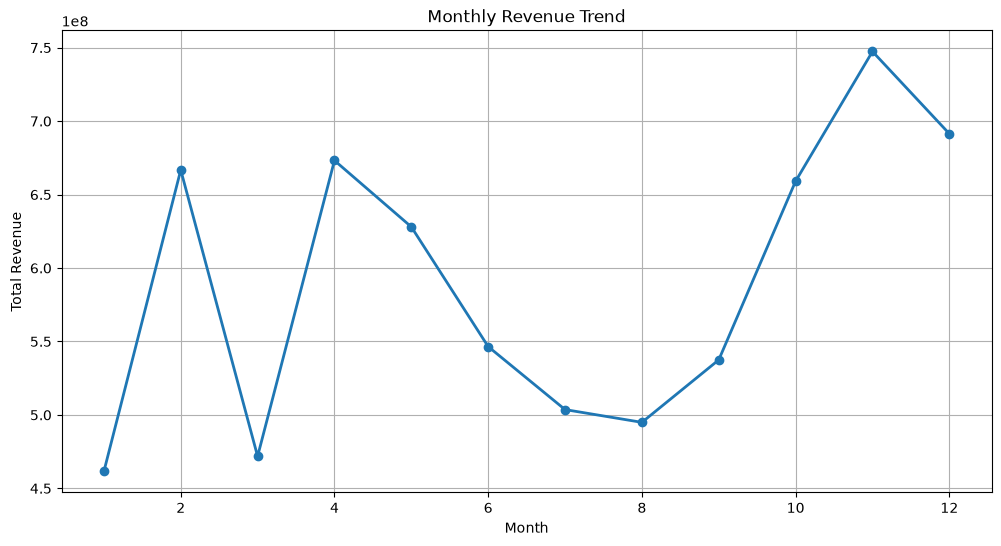

In [44]:
monthly_revenue = df.groupby('Month')['Revenue'].sum() 
plt.figure(figsize=(12,6)) 
plt.plot( monthly_revenue.index, monthly_revenue.values, marker='o', linewidth=2 ) 
plt.title('Monthly Revenue Trend') 
plt.xlabel('Month') 
plt.ylabel('Total Revenue') 
plt.grid(True) 
plt.show()

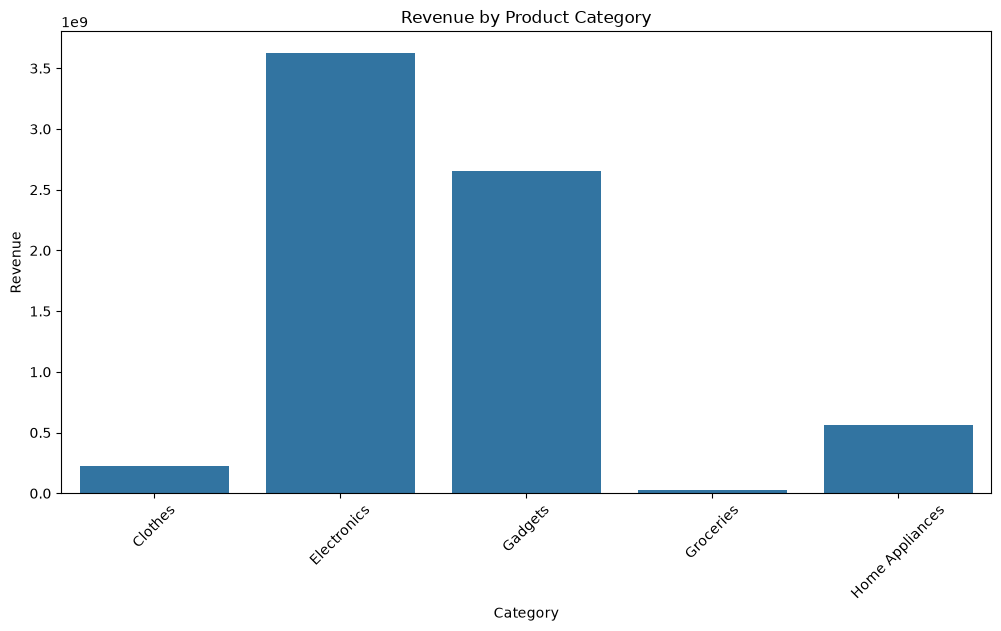

In [20]:
category_revenue = df.groupby('Category')['Revenue'].sum() 
plt.figure(figsize=(12,6)) 
sns.barplot( x=category_revenue.index, y=category_revenue.values ) 
plt.title('Revenue by Product Category') 
plt.xlabel('Category') 
plt.ylabel('Revenue') 
plt.xticks(rotation=45) 
plt.show()

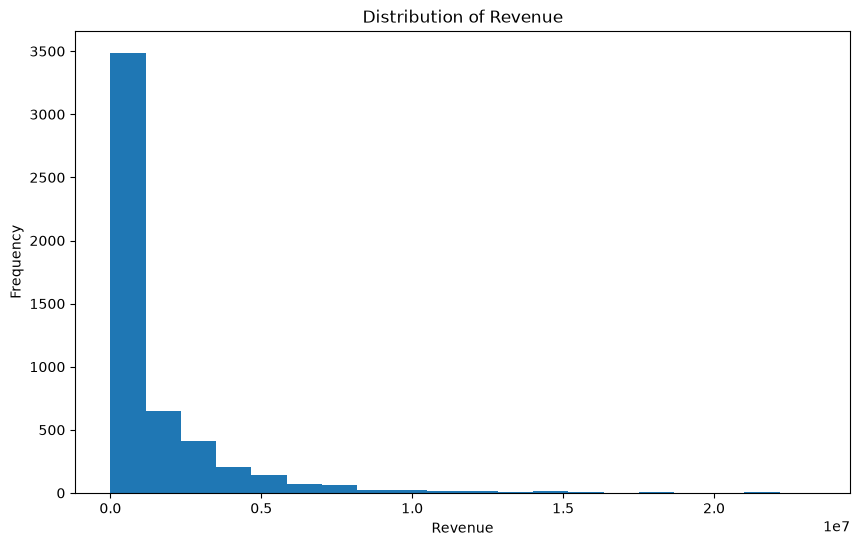

In [41]:
plt.figure(figsize=(10,6)) 
plt.hist( df['Revenue'], bins=20 ) 
plt.title('Distribution of Revenue') 
plt.xlabel('Revenue') 
plt.ylabel('Frequency') 
plt.show()

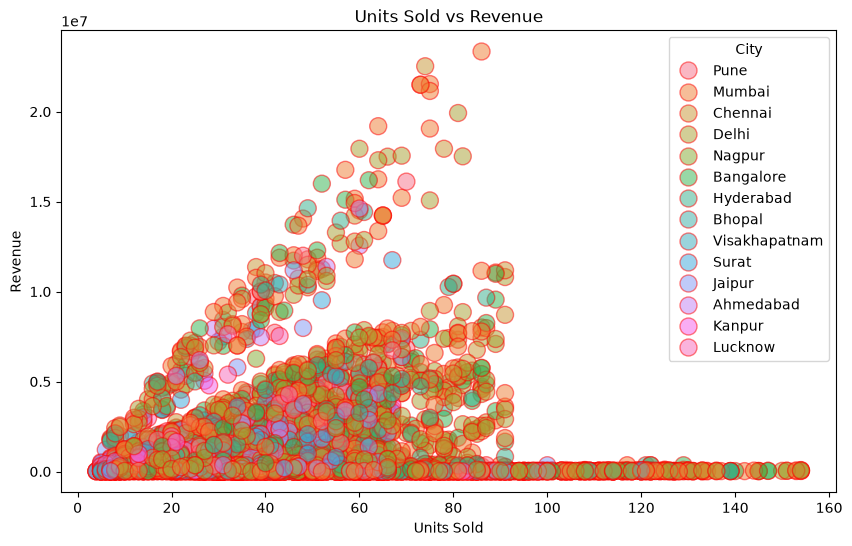

In [45]:
plt.figure(figsize=(10,6)) 
sns.scatterplot( data=df, x='Units_Sold', y='Revenue',s=150 , alpha=0.5, edgecolor='red', markers='^',hue='City') 
plt.title('Units Sold vs Revenue') 
plt.xlabel('Units Sold') 
plt.ylabel('Revenue') 
plt.show()

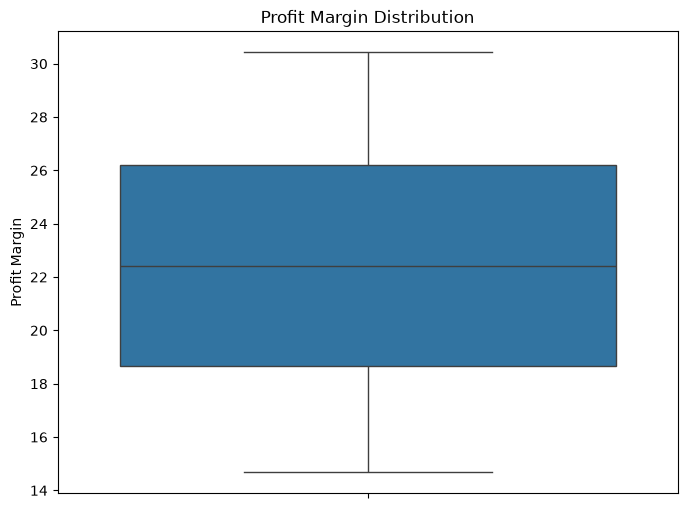

In [35]:
plt.figure(figsize=(8,6)) 
sns.boxplot( y=df['Profit_Margin'] ) 
plt.title('Profit Margin Distribution') 
plt.ylabel('Profit Margin') 
plt.show()

In [36]:
monthly_revenue = df.groupby('Month')['Revenue'].sum() 
highest_month = monthly_revenue.idxmax() 
highest_revenue = monthly_revenue.max() 
print("Highest Revenue Month:", highest_month) 
print("Revenue:", highest_revenue)

Highest Revenue Month: 11
Revenue: 747399643.0


In [38]:
category_revenue = df.groupby('City')['Revenue'].sum() 
top_category = category_revenue.idxmax() 
top_revenue = category_revenue.max() 
print("Top City:", top_category) 
print("Revenue:", top_revenue)

Top City: Mumbai
Revenue: 1674840467.0
